# Predicción del éxito de cosecha de manzanas con un robot humanoide

**Proyecto final — Ciencia de Datos e Inteligencia Artificial aplicados a la Mecatrónica (UTEC, 2026/2)**

Un robot Unitree G1 con mano Dex3 cosecha manzanas: la cámara de la cabeza (Intel RealSense D435i) detecta la
fruta, una política de aprendizaje por refuerzo lleva el brazo hasta ella, la mano la agarra, se desprende del
pedúnculo y se lleva a una canasta. No todos los intentos terminan bien: el brazo puede no llegar, el agarre
puede quedar flojo, el pedúnculo puede no cortarse, o la fruta puede caerse en el camino.

**Pregunta:** *antes de intentar*, con lo que el robot ya sabe (dónde está la manzana y qué vecinas ve la
cámara), ¿se puede predecir

1. si el intento terminará con la manzana en la canasta? (clasificación binaria), y
2. en qué etapa fallará? (clasificación multiclase)

Una buena predicción sirve para elegir qué manzana intentar primero y para no gastar tiempo y batería en
intentos con baja probabilidad de éxito.

**Datos:** generados en simulación (Isaac Lab) con la misma secuencia y las mismas políticas que corre el robot
real (`ml_project/recolectar_dataset.py`). Cada fila es un intento sobre un árbol aleatorio. La validación
también es en simulación (no es posible validar en el robot real en el plazo del proyecto).

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, learning_curve,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
import time
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
import sklearn, matplotlib

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
DATOS = os.environ.get("ML_DATOS", "datos")          # carpeta con los CSV de recolectar_dataset.py
FIG = os.environ.get("ML_FIG", "figuras")             # figuras para el reporte
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, nombre + ".png"), dpi=200, bbox_inches="tight")

print("python numpy pandas sklearn matplotlib:", np.__version__, pd.__version__, sklearn.__version__,
      matplotlib.__version__)

python numpy pandas sklearn matplotlib: 2.1.3 2.3.1 1.8.0 3.9.2


## 1. Carga de los datos

Se leen todos los CSV de `datos/` (una corrida de simulación por semilla). Se descartan los intentos cuya
manzana objetivo no está entera dentro del cuadro de la cámara: el robot real no intentaría una manzana que no
ve.

In [2]:
archivos = sorted(glob.glob(os.path.join(DATOS, "*.csv")))
df = pd.concat([pd.read_csv(f) for f in archivos], ignore_index=True)
print(f"{len(archivos)} archivo(s), {len(df)} intentos, semillas {sorted(df.semilla.unique())}")
n0 = len(df)
df = df[df.objetivo_visible == 1].copy()
print(f"descartados por objetivo fuera del cuadro de la cámara: {n0 - len(df)}")
df.head()

3 archivo(s), 2604 intentos, semillas [np.int64(0), np.int64(1), np.int64(2)]
descartados por objetivo fuera del cuadro de la cámara: 41


,episodio,semilla,env,t_inicio_s,objetivo_visible,yaw_cintura_deg,x_hombro_m,y_hombro_m,z_hombro_m,dist_hombro_m,...,n_vecinos_vis_15cm,n_vecinos_vis_debajo,n_manzanas_arbol,n_vecinos_ocultos,exito,etapa,estado_fallo,motivo,error_alcance_cm,duracion_s
0,0,0,2,0.5,1,10.95145,0.33081,-0.09507,-0.45541,0.57085,...,0,0,4,2,0,alcance,approach,the hand ended 12.3 cm from the apple goal (ti...,12.30,13.76
1,1,0,14,0.5,1,-12.04602,0.32199,-0.12348,-0.41175,0.53709,...,0,0,2,1,0,alcance,approach,the hand ended 6.4 cm from the apple goal (tim...,6.40,15.92
2,2,0,13,0.5,1,11.94342,0.35975,0.00567,-0.07349,0.36723,...,0,2,4,1,0,agarre,grasp,nothing between the fingers after the close,1.59,16.00
3,3,0,8,0.5,1,-7.09053,0.31492,-0.08892,-0.38849,0.50794,...,0,0,5,3,0,agarre,grasp,nothing between the fingers after the close,0.77,16.10
4,4,0,3,0.5,1,9.29073,0.32979,-0.17209,-0.28076,0.46605,...,0,0,3,2,0,agarre,grasp,nothing between the fingers after the close,1.82,17.68


In [3]:
print("Resultado de los intentos (etapa donde terminó):")
t = df.etapa.value_counts()
display(pd.DataFrame({"intentos": t, "proporción": (t / len(df)).round(3)}))
print(f"tasa de éxito global: {df.exito.mean():.1%}")

Resultado de los intentos (etapa donde terminó):


,intentos,proporción
etapa,,
exito,954,0.372
agarre,700,0.273
desprendimiento,496,0.194
alcance,222,0.087
transporte,127,0.050
retorno,55,0.021
deposito,9,0.004


tasa de éxito global: 37.2%


## 2. Análisis de las características

### 2.1 Naturaleza de cada variable

Todas las entradas se conocen **antes** del intento (el robot las obtiene de la cámara y de su propio estado).
Las variables que solo existen en simulación o que describen el resultado (`error_alcance_cm`, `duracion_s`,
`motivo`, `n_vecinos_ocultos`, `n_manzanas_arbol`) **no** se usan como entradas: usarlas sería una fuga de
información (*data leakage*). La distancia al tronco tampoco se usa: en el robot real todavía no se estima de
forma confiable.

Dos columnas del CSV se descartan por cómo está construida la simulación: `radio_manzana_m` (el simulador fija
un radio por entorno al arrancar, así que solo actuaría como identificador del entorno) y `n_vecinos_vis_15cm`
(los vecinos se colocan a 10 cm o más de superficie a superficie, por lo que siempre vale 0).

In [4]:
ENTRADAS = ["yaw_cintura_deg", "x_hombro_m", "y_hombro_m", "z_hombro_m", "dist_hombro_m", "dist_horiz_m",
            "azimut_deg", "elevacion_deg", "u_px", "v_px", "prof_cam_m",
            "n_vecinos_vis", "dist_vecino_min_m", "vec_dx_m", "vec_dy_m", "vec_dz_m",
            "n_vecinos_vis_debajo", "hay_vecino_vis"]
DISCRETAS = {"n_vecinos_vis", "n_vecinos_vis_debajo", "hay_vecino_vis"}
DESCRIPCION = {
    "yaw_cintura_deg": "giro de la cintura con que se ve el árbol",
    "x_hombro_m": "manzana respecto al hombro derecho, hacia adelante (marco del torso)",
    "y_hombro_m": "manzana respecto al hombro, hacia la izquierda",
    "z_hombro_m": "manzana respecto al hombro, hacia arriba",
    "dist_hombro_m": "distancia 3D hombro-manzana",
    "dist_horiz_m": "distancia horizontal hombro-manzana",
    "azimut_deg": "ángulo horizontal de la manzana visto desde el hombro",
    "elevacion_deg": "ángulo vertical de la manzana visto desde el hombro",
    "u_px": "columna del centro de la manzana en la imagen (424 px)",
    "v_px": "fila del centro de la manzana en la imagen (240 px)",
    "prof_cam_m": "profundidad medida por la cámara",
    "radio_manzana_m": "radio de la manzana",
    "n_vecinos_vis": "manzanas vecinas que la cámara ve enteras",
    "dist_vecino_min_m": "distancia al vecino visible más cercano (sin vecino: 0.5 m)",
    "vec_dx_m": "vecino más cercano respecto al objetivo, adelante (sin vecino: 0)",
    "vec_dy_m": "vecino más cercano respecto al objetivo, izquierda (sin vecino: 0)",
    "vec_dz_m": "vecino más cercano respecto al objetivo, arriba (sin vecino: 0)",
    "n_vecinos_vis_15cm": "vecinos visibles a menos de 15 cm",
    "n_vecinos_vis_debajo": "vecinos visibles debajo del objetivo (a < 15 cm en horizontal)",
    "hay_vecino_vis": "1 si la cámara ve al menos un vecino",
}

# sin vecino visible: distancia "lejos" (0.5 m) y desplazamientos 0, con un indicador aparte
df["hay_vecino_vis"] = df.n_vecinos_vis.gt(0).astype(int)
df["dist_vecino_min_m"] = df.dist_vecino_min_m.fillna(0.5)
for c in ["vec_dx_m", "vec_dy_m", "vec_dz_m"]:
    df[c] = df[c].fillna(0.0)

tabla = pd.DataFrame({
    "descripción": [DESCRIPCION[c] for c in ENTRADAS],
    "tipo": ["discreta" if c in DISCRETAS else "continua" for c in ENTRADAS],
    "rol": "independiente (entrada)",
})
tabla.index = ENTRADAS
tabla.loc["exito"] = ["1 = manzana depositada en la canasta", "discreta (binaria)", "dependiente (salida 1)"]
tabla.loc["etapa"] = ["etapa donde terminó el intento", "discreta (categórica)", "dependiente (salida 2)"]
tabla

,descripción,tipo,rol
yaw_cintura_deg,giro de la cintura con que se ve el árbol,continua,independiente (entrada)
x_hombro_m,"manzana respecto al hombro derecho, hacia adel...",continua,independiente (entrada)
y_hombro_m,"manzana respecto al hombro, hacia la izquierda",continua,independiente (entrada)
z_hombro_m,"manzana respecto al hombro, hacia arriba",continua,independiente (entrada)
dist_hombro_m,distancia 3D hombro-manzana,continua,independiente (entrada)
dist_horiz_m,distancia horizontal hombro-manzana,continua,independiente (entrada)
azimut_deg,ángulo horizontal de la manzana visto desde el...,continua,independiente (entrada)
elevacion_deg,ángulo vertical de la manzana visto desde el h...,continua,independiente (entrada)
u_px,columna del centro de la manzana en la imagen ...,continua,independiente (entrada)
v_px,fila del centro de la manzana en la imagen (24...,continua,independiente (entrada)


In [5]:
df[ENTRADAS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
yaw_cintura_deg,2563.0,0.050,8.559,-14.998,-7.247,-0.106,7.363,14.993
x_hombro_m,2563.0,0.338,0.040,0.227,0.312,0.336,0.363,0.479
y_hombro_m,2563.0,-0.068,0.065,-0.239,-0.114,-0.077,-0.027,0.183
z_hombro_m,2563.0,-0.260,0.102,-0.474,-0.349,-0.257,-0.190,-0.002
dist_hombro_m,2563.0,0.445,0.068,0.245,0.391,0.439,0.502,0.627
dist_horiz_m,2563.0,0.351,0.040,0.232,0.325,0.351,0.376,0.494
azimut_deg,2563.0,-11.224,10.638,-35.451,-19.021,-12.930,-4.484,27.238
elevacion_deg,2563.0,-35.297,11.564,-53.696,-44.624,-37.694,-28.155,-0.293
u_px,2563.0,336.733,37.328,182.267,314.567,344.090,364.251,401.806
v_px,2563.0,159.015,42.628,28.568,132.630,168.569,194.612,221.080


### 2.2 Análisis individual: distribución de cada variable según el resultado

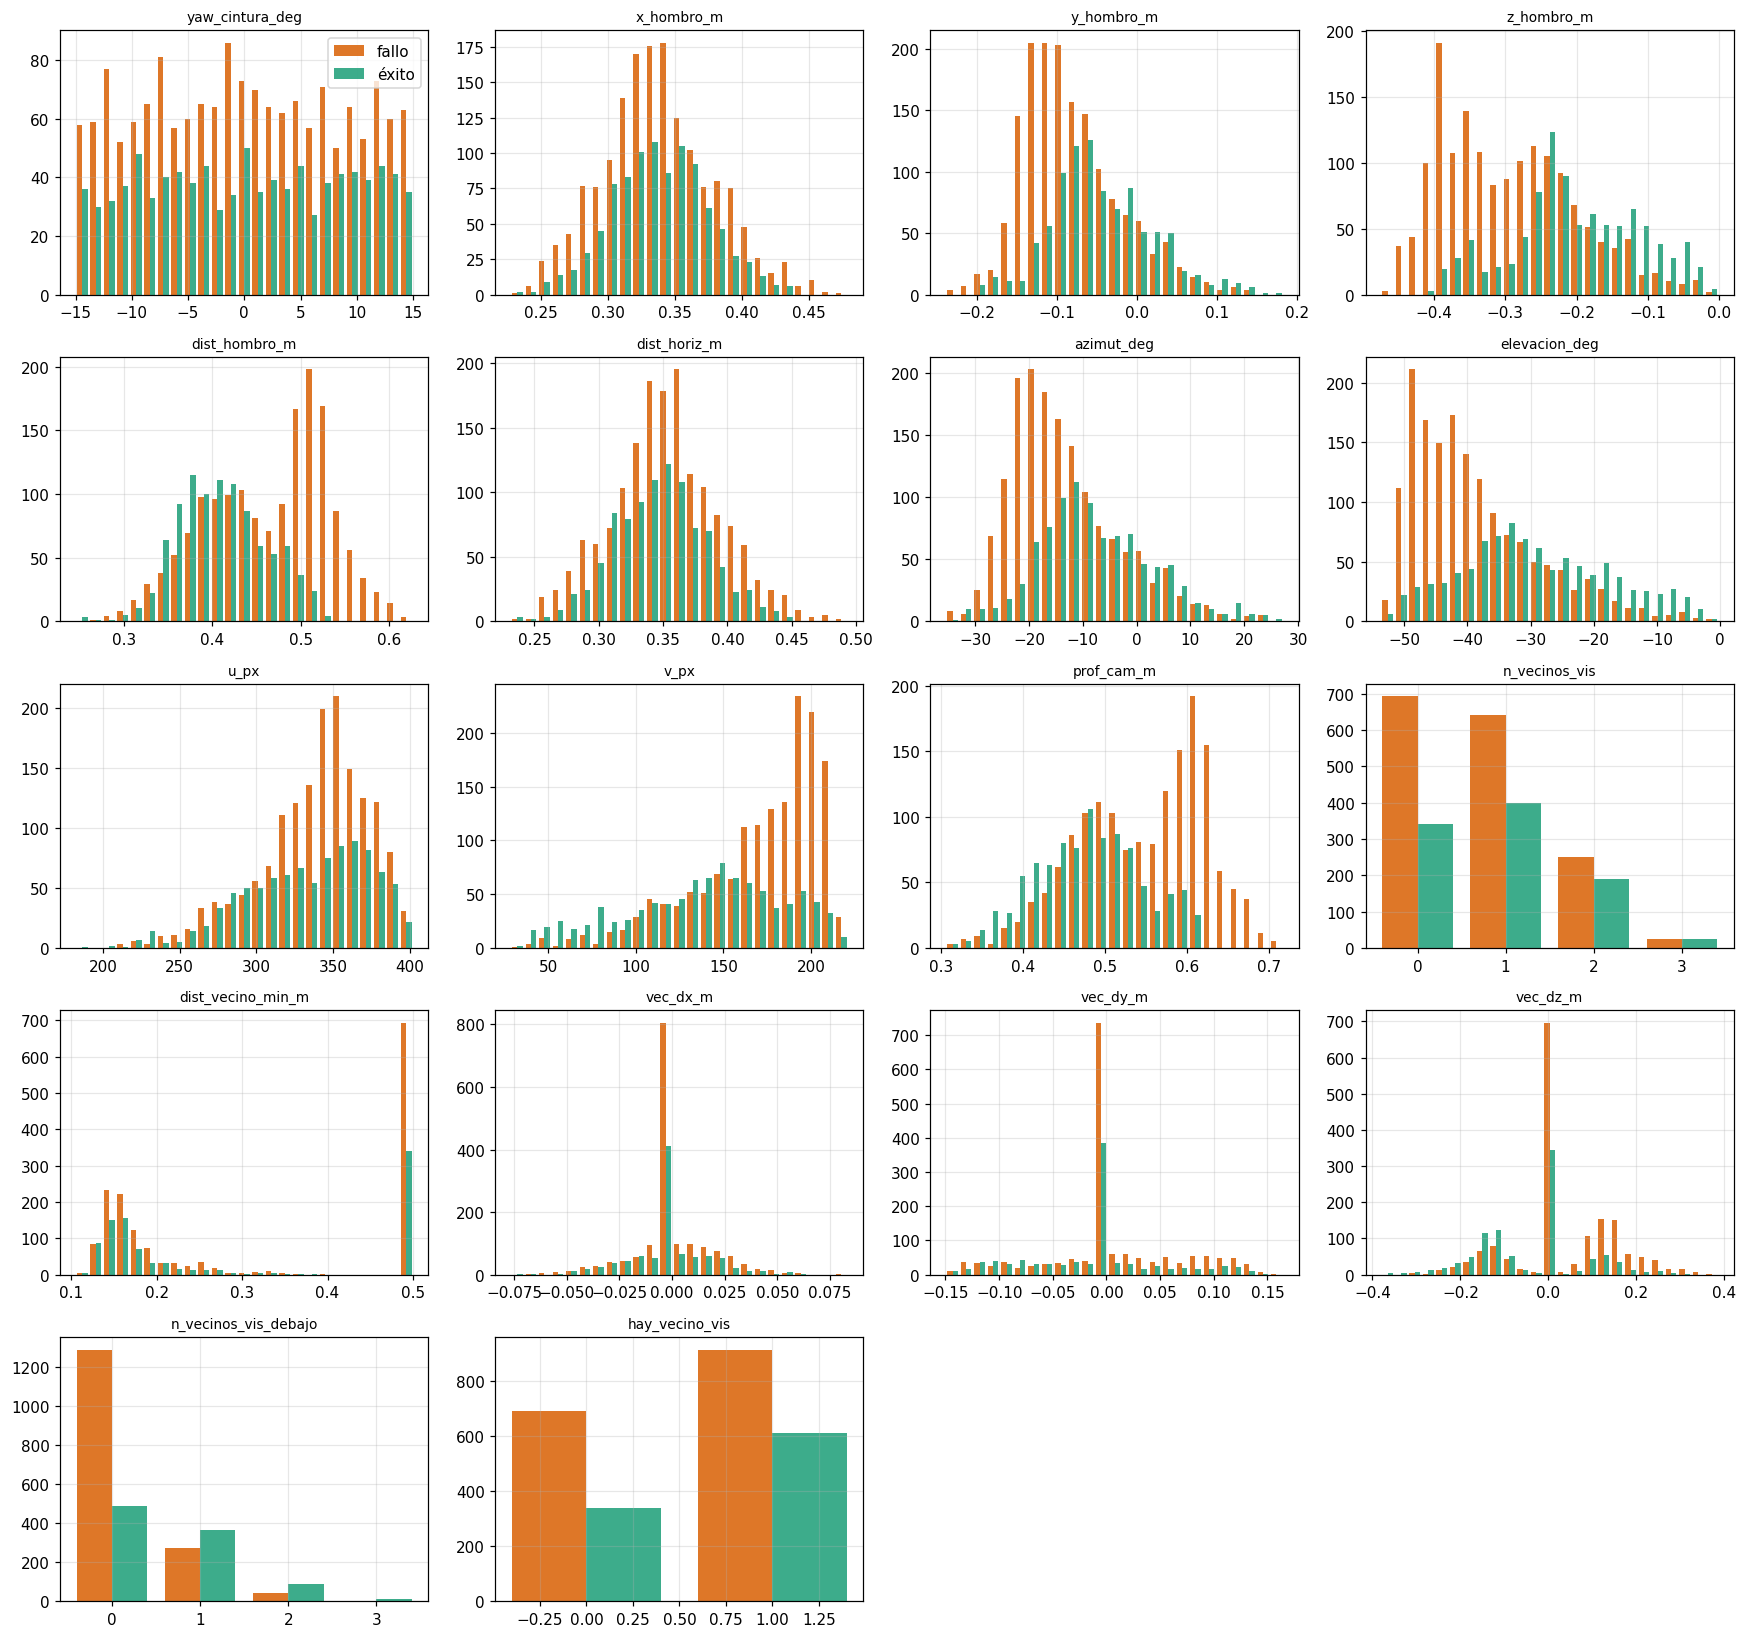

In [6]:
n = len(ENTRADAS)
cols = 4
fig, axs = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(16, 3.0 * np.ceil(n / cols)))
for ax, c in zip(axs.flat, ENTRADAS):
    ok, ko = df.loc[df.exito == 1, c], df.loc[df.exito == 0, c]
    bins = np.arange(df[c].min() - 0.5, df[c].max() + 1.5) if c in DISCRETAS else 25
    ax.hist([ko, ok], bins=bins, label=["fallo", "éxito"], color=["#d95f02", "#1b9e77"], alpha=0.85)
    ax.set_title(c, fontsize=9)
for ax in list(axs.flat)[n:]:
    ax.axis("off")
axs.flat[0].legend()
guardar("distribuciones")
plt.show()

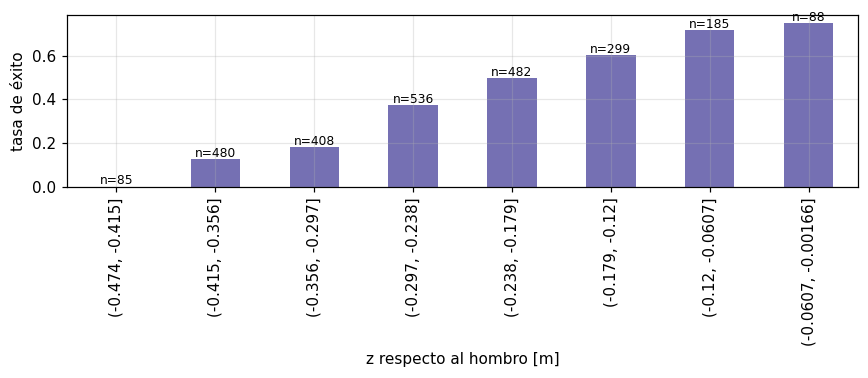

In [7]:
# tasa de éxito por altura de la manzana respecto al hombro (en el robot real la altura fue decisiva)
bins = pd.cut(df.z_hombro_m, bins=8)
g = df.groupby(bins, observed=True).exito.agg(["mean", "count"])
ax = g["mean"].plot(kind="bar", figsize=(8, 3.5), color="#7570b3")
ax.set_ylabel("tasa de éxito"); ax.set_xlabel("z respecto al hombro [m]")
for k, (m, c) in enumerate(g.values):
    ax.text(k, m + 0.01, f"n={int(c)}", ha="center", fontsize=8)
guardar("exito_vs_altura")
plt.show()

### 2.3 Análisis colectivo: mapa de correlaciones

Correlación de Pearson entre las entradas y con la salida binaria (para una salida binaria, la correlación de
Pearson es la correlación punto-biserial).

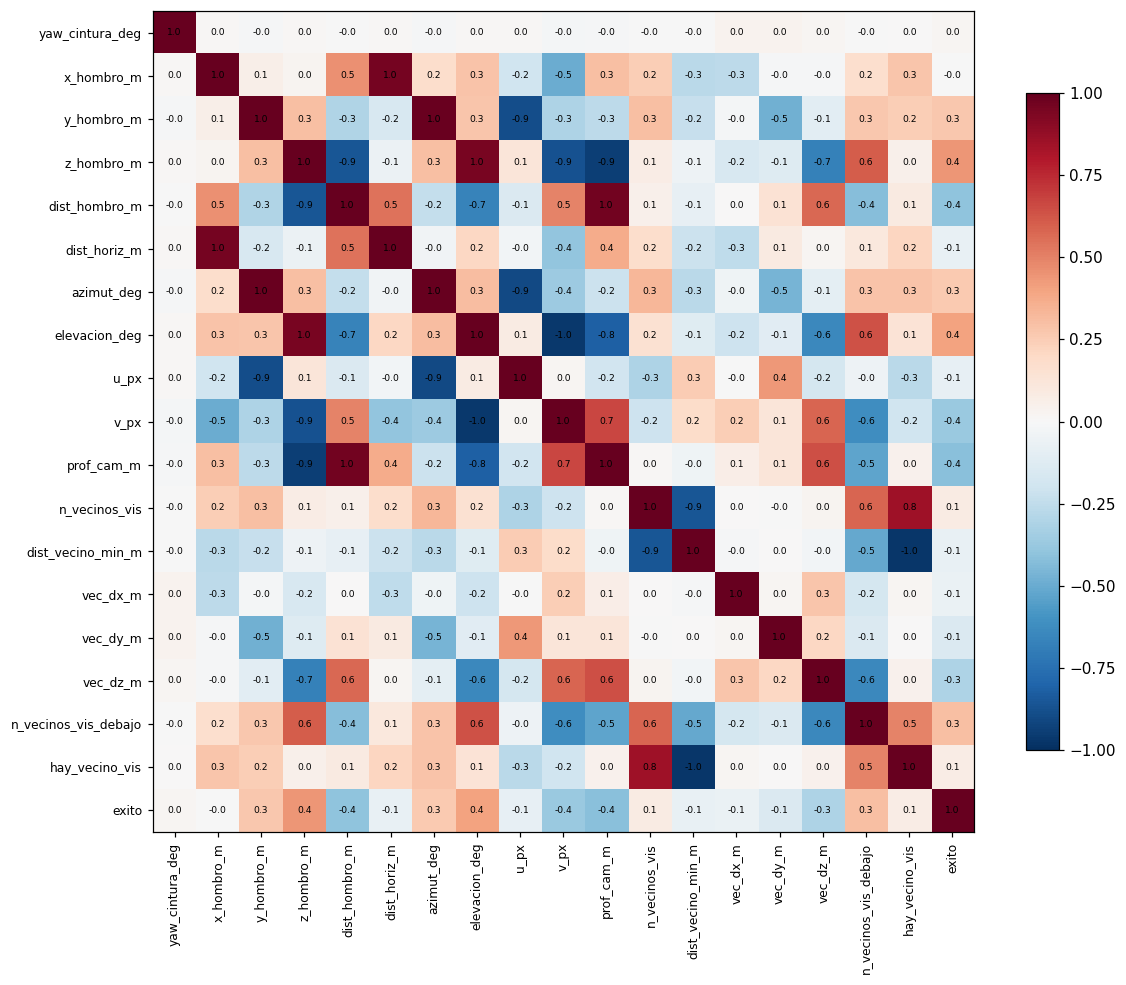

Correlación de cada entrada con el éxito:
z_hombro_m              0.438
prof_cam_m             -0.418
elevacion_deg           0.401
dist_hombro_m          -0.401
v_px                   -0.373
vec_dz_m               -0.308
n_vecinos_vis_debajo    0.303
y_hombro_m              0.269
azimut_deg              0.263
vec_dy_m               -0.148
u_px                   -0.085
n_vecinos_vis           0.085
dist_vecino_min_m      -0.078
dist_horiz_m           -0.076
hay_vecino_vis          0.072
vec_dx_m               -0.068
yaw_cintura_deg         0.017
x_hombro_m             -0.005


In [8]:
corr = df[ENTRADAS + ["exito"]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.grid(False)
guardar("correlaciones")
plt.show()
print("Correlación de cada entrada con el éxito:")
print(corr["exito"].drop("exito").sort_values(key=np.abs, ascending=False).round(3).to_string())

Varias entradas son redundantes por construcción (por ejemplo `dist_hombro_m` con `dist_horiz_m`, o el píxel
`v_px` con la altura): describen la misma posición en otros sistemas de coordenadas. Los modelos lineales sufren
con la colinealidad, por eso se usa regularización; los árboles no se ven afectados.

### 2.4 Tipo de entrenamiento

Cada intento tiene su **respuesta real** (la simulación registra si la manzana llegó a la canasta y, si no, en
qué etapa falló). Hay retroalimentación completa, por lo tanto el aprendizaje es **supervisado**, y la salida
es categórica: **clasificación** (binaria y multiclase).

## 3. Definición de los modelos

Se eligen modelos de `scikit-learn` de naturalezas distintas:

| modelo | por qué |
|---|---|
| Regresión logística (L2) | línea de base interpretable; probabilidades bien calibradas |
| k vecinos más cercanos (k-NN) | el éxito depende de la zona del espacio de trabajo: manzanas parecidas tienen resultados parecidos |
| Máquina de vectores de soporte (kernel RBF) | frontera no lineal suave (el espacio alcanzable del brazo es curvo) |
| Bosque aleatorio | interacciones entre variables (altura × vecinos), robusto a la colinealidad |
| Gradient boosting | suele ser el más preciso en datos tabulares; permite ver el desempeño por iteración ("épocas") |
| Red neuronal (perceptrón multicapa, MLP) | aproximador no lineal general; se compara con el bosque aleatorio en la sección 4.3 |

Además, un **clasificador trivial** (siempre la clase más frecuente) como referencia mínima.

**Partición:** la corrida de la semilla 1 es el **conjunto de prueba**
(intentos simulados en una corrida independiente: validación en simulación); las demás semillas son el
entrenamiento. Si no hay datos de la semilla 1, se usa un 20 % estratificado. Los
hiperparámetros se eligen con validación cruzada estratificada de 5 particiones **solo** sobre el
entrenamiento.

In [9]:
semillas = sorted(df.semilla.unique())
SEMILLA_TEST = int(os.environ.get("ML_SEMILLA_TEST", 1))     # la corrida reservada para la prueba
if len(semillas) > 1 and SEMILLA_TEST in semillas:
    train, test = df[df.semilla != SEMILLA_TEST], df[df.semilla == SEMILLA_TEST]
    print(f"prueba = corrida independiente (semilla {SEMILLA_TEST})")
else:
    train, test = train_test_split(df, test_size=0.2, stratify=df.exito, random_state=SEED)
    print("prueba = 20 % estratificado")
X_tr, X_te = train[ENTRADAS].values, test[ENTRADAS].values
y_tr, y_te = train.exito.values, test.exito.values
print(f"entrenamiento {len(train)} (éxito {y_tr.mean():.1%}), prueba {len(test)} (éxito {y_te.mean():.1%})")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

prueba = corrida independiente (semilla 1)
entrenamiento 1971 (éxito 35.7%), prueba 592 (éxito 42.2%)


In [10]:
def pipe(modelo):
    return Pipeline([("escala", StandardScaler()), ("modelo", modelo)])

MODELOS = {
    "Trivial": (pipe(DummyClassifier(strategy="most_frequent")), {}),
    "Regresión logística": (pipe(LogisticRegression(max_iter=2000)),
                            {"modelo__C": [0.01, 0.1, 1, 10, 100]}),
    "k-NN": (pipe(KNeighborsClassifier()),
             {"modelo__n_neighbors": [5, 11, 21, 41], "modelo__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (pipe(SVC(kernel="rbf", probability=True, random_state=SEED)),
                  {"modelo__C": [0.3, 1, 3, 10], "modelo__gamma": ["scale", 0.03, 0.1]}),
    "Bosque aleatorio": (pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
                         {"modelo__max_depth": [4, 8, None], "modelo__min_samples_leaf": [1, 5, 20]}),
    "Gradient boosting": (pipe(GradientBoostingClassifier(random_state=SEED)),
                          {"modelo__n_estimators": [100, 300], "modelo__learning_rate": [0.03, 0.1],
                           "modelo__max_depth": [2, 3]}),
    "Red neuronal (MLP)": (pipe(MLPClassifier(max_iter=2000, early_stopping=True, validation_fraction=0.15,
                                              n_iter_no_change=30, random_state=SEED)),
                           {"modelo__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)],
                            "modelo__alpha": [1e-3, 1e-2, 0.1, 1.0, 3.0, 10.0]}),
}

ajustados = {}
for nombre, (est, grid) in MODELOS.items():
    gs = GridSearchCV(est, grid or {"escala": [StandardScaler()]}, scoring="roc_auc", cv=CV, n_jobs=-1)
    gs.fit(X_tr, y_tr)
    ajustados[nombre] = gs
    print(f"{nombre:22s} AUC-VC {gs.best_score_:.3f}   {gs.best_params_ if grid else ''}")

Trivial                AUC-VC 0.500   


Regresión logística    AUC-VC 0.802   {'modelo__C': 100}
k-NN                   AUC-VC 0.816   {'modelo__n_neighbors': 41, 'modelo__weights': 'distance'}


SVM (RBF)              AUC-VC 0.819   {'modelo__C': 1, 'modelo__gamma': 'scale'}


Bosque aleatorio       AUC-VC 0.843   {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 5}


Gradient boosting      AUC-VC 0.835   {'modelo__learning_rate': 0.1, 'modelo__max_depth': 2, 'modelo__n_estimators': 300}


Red neuronal (MLP)     AUC-VC 0.812   {'modelo__alpha': 1.0, 'modelo__hidden_layer_sizes': (32, 16)}


## 4. Análisis comparativo — salida binaria (¿llega a la canasta?)

**Métricas elegidas y por qué:**

* **Exactitud** (*accuracy*): proporción de aciertos; fácil de leer, pero engañosa si las clases están
  desbalanceadas (por eso se compara contra el clasificador trivial).
* **Precisión** de la clase éxito: de los intentos que el modelo aprueba, cuántos salen bien — es lo que
  importa si el robot solo intenta las manzanas aprobadas.
* **Exhaustividad** (*recall*): de las manzanas cosechables, cuántas aprueba (las no aprobadas se pierden).
* **F1**: media armónica de las dos anteriores.
* **AUC-ROC**: calidad del ordenamiento por probabilidad, sin depender de un umbral — sirve para elegir qué
  manzana intentar primero.
* **Brier**: error cuadrático medio de la probabilidad predicha (calibración).
* **Intervalo de confianza del 95 %** de la exactitud y el AUC, por *bootstrap* del conjunto de prueba (1000
  remuestreos), para saber si las diferencias entre modelos son reales o ruido.

In [11]:
rng = np.random.default_rng(SEED)
B = rng.integers(0, len(y_te), size=(1000, len(y_te)))

def ic95(fn, y, p):
    vals = []
    for b in B:
        if len(np.unique(y[b])) < 2:
            continue
        vals.append(fn(y[b], p[b]))
    return np.percentile(vals, [2.5, 97.5])

filas, PROBA = [], {}
for nombre, gs in ajustados.items():
    p = gs.predict_proba(X_te)[:, 1]
    yhat = (p >= 0.5).astype(int)
    PROBA[nombre] = p
    auc = roc_auc_score(y_te, p) if nombre != "Trivial" else 0.5
    a_lo, a_hi = ic95(lambda y, q: accuracy_score(y, q >= 0.5), y_te, p)
    u_lo, u_hi = ic95(roc_auc_score, y_te, p) if nombre != "Trivial" else (0.5, 0.5)
    filas.append({"modelo": nombre, "exactitud": accuracy_score(y_te, yhat), "IC95 exactitud": f"[{a_lo:.3f}, {a_hi:.3f}]",
                  "precisión": precision_score(y_te, yhat, zero_division=0),
                  "exhaustividad": recall_score(y_te, yhat, zero_division=0),
                  "F1": f1_score(y_te, yhat, zero_division=0), "AUC-ROC": auc, "IC95 AUC": f"[{u_lo:.3f}, {u_hi:.3f}]",
                  "Brier": brier_score_loss(y_te, p), "AUC-VC (entren.)": gs.best_score_})
res_bin = pd.DataFrame(filas).set_index("modelo").round(3)
res_bin.to_csv(os.path.join(FIG, "tabla_binaria.csv"))
res_bin

,exactitud,IC95 exactitud,precisión,exhaustividad,F1,AUC-ROC,IC95 AUC,Brier,AUC-VC (entren.)
modelo,,,,,,,,,
Trivial,0.578,"[0.537, 0.617]",0.000,0.000,0.000,0.500,"[0.500, 0.500]",0.422,0.500
Regresión logística,0.666,"[0.627, 0.704]",0.626,0.516,0.566,0.747,"[0.704, 0.785]",0.204,0.802
k-NN,0.704,"[0.666, 0.742]",0.667,0.600,0.632,0.772,"[0.733, 0.809]",0.195,0.816
SVM (RBF),0.682,"[0.644, 0.720]",0.667,0.496,0.569,0.780,"[0.742, 0.818]",0.200,0.819
Bosque aleatorio,0.718,"[0.681, 0.752]",0.684,0.616,0.648,0.814,"[0.780, 0.847]",0.174,0.843
Gradient boosting,0.686,"[0.647, 0.723]",0.650,0.556,0.599,0.796,"[0.759, 0.830]",0.185,0.835
Red neuronal (MLP),0.694,"[0.657, 0.730]",0.656,0.580,0.616,0.786,"[0.747, 0.819]",0.189,0.812


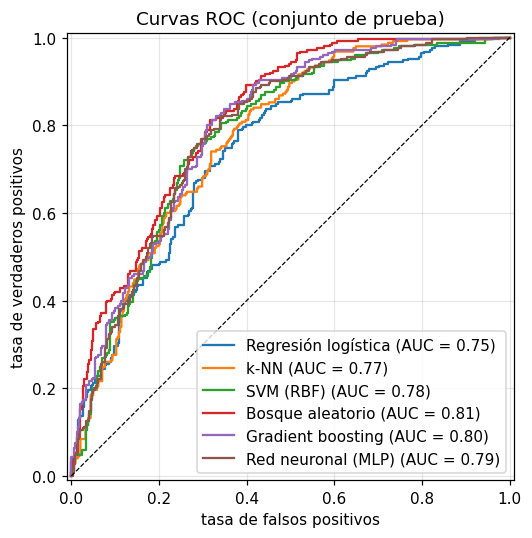

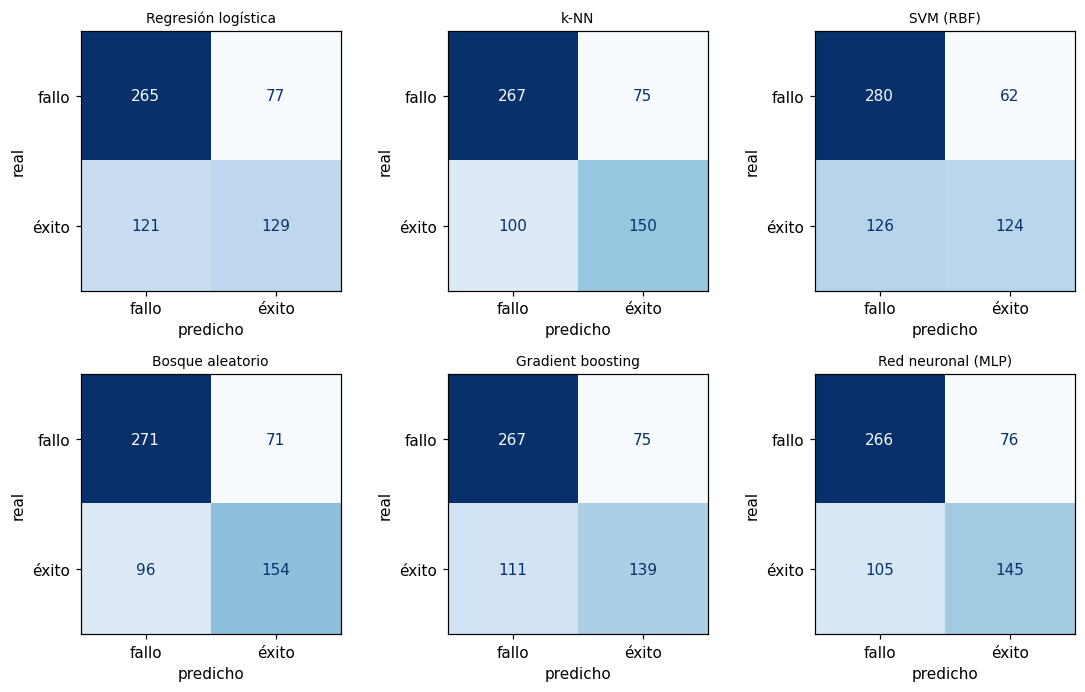

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
for nombre, p in PROBA.items():
    if nombre != "Trivial":
        RocCurveDisplay.from_predictions(y_te, p, name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("tasa de falsos positivos"); ax.set_ylabel("tasa de verdaderos positivos")
ax.set_title("Curvas ROC (conjunto de prueba)")
guardar("roc")
plt.show()

nombres = [n for n in ajustados if n != "Trivial"]
fig, axs = plt.subplots(2, (len(nombres) + 1) // 2, figsize=(3.4 * ((len(nombres) + 1) // 2), 6.4))
axs = axs.ravel()
for ax in axs[len(nombres):]:
    ax.axis("off")
for ax, nombre in zip(axs, nombres):
    ConfusionMatrixDisplay.from_predictions(y_te, (PROBA[nombre] >= 0.5).astype(int), display_labels=["fallo", "éxito"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre, fontsize=9); ax.grid(False)
    ax.set_xlabel("predicho"); ax.set_ylabel("real")
guardar("confusion_binaria")
plt.show()

### 4.1 Desempeño según la cantidad de datos y las "épocas" de entrenamiento

* **Curva de aprendizaje:** AUC en validación cruzada al entrenar con el 10 % … 100 % del conjunto de
  entrenamiento. Indica si conviene simular más intentos.
* **Gradient boosting por iteración:** cada árbol nuevo es una "época"; se muestra el AUC en entrenamiento y en
  prueba después de cada árbol (sobreajuste cuando las curvas se separan).

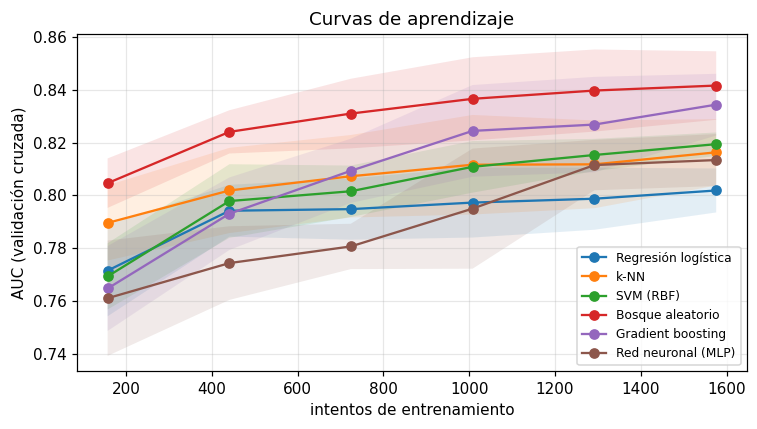

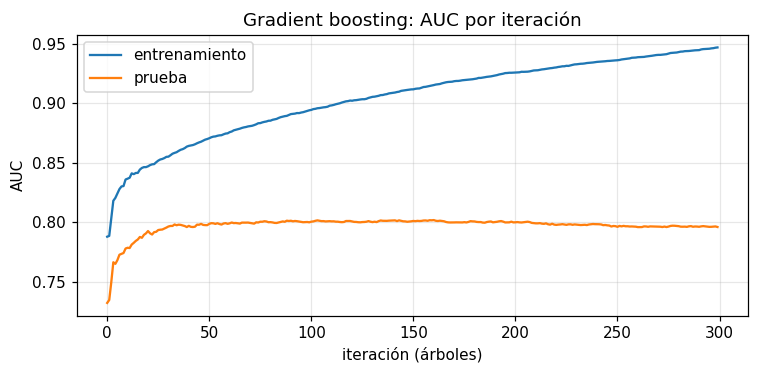

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for nombre in nombres:
    tam, tr, va = learning_curve(ajustados[nombre].best_estimator_, X_tr, y_tr, cv=CV, scoring="roc_auc",
                                 train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=SEED, shuffle=True)
    ax.plot(tam, va.mean(1), "o-", label=nombre)
    ax.fill_between(tam, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.12)
ax.set_xlabel("intentos de entrenamiento"); ax.set_ylabel("AUC (validación cruzada)")
ax.set_title("Curvas de aprendizaje"); ax.legend(fontsize=8)
guardar("curvas_aprendizaje")
plt.show()

gb = ajustados["Gradient boosting"].best_estimator_
Xs_tr, Xs_te = gb[:-1].transform(X_tr), gb[:-1].transform(X_te)
auc_tr = [roc_auc_score(y_tr, p[:, 1]) for p in gb[-1].staged_predict_proba(Xs_tr)]
auc_te = [roc_auc_score(y_te, p[:, 1]) for p in gb[-1].staged_predict_proba(Xs_te)]
plt.figure(figsize=(7, 3.5))
plt.plot(auc_tr, label="entrenamiento"); plt.plot(auc_te, label="prueba")
plt.xlabel("iteración (árboles)"); plt.ylabel("AUC"); plt.title("Gradient boosting: AUC por iteración"); plt.legend()
guardar("gb_iteraciones")
plt.show()

### 4.2 ¿Qué variables usa el mejor modelo?

Importancia por permutación en el conjunto de prueba: cuánto cae el AUC al desordenar cada variable.

mejor modelo por AUC en prueba: Bosque aleatorio


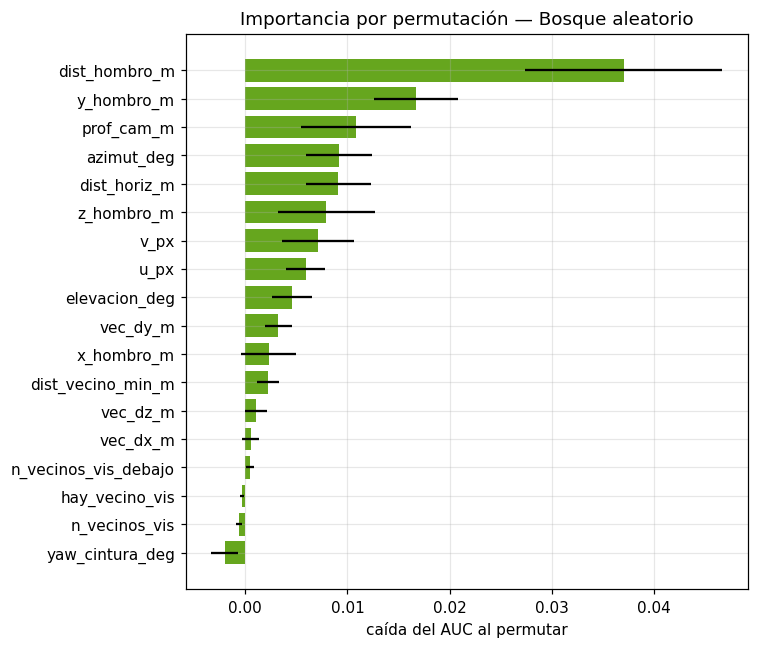

In [14]:
mejor = res_bin.drop("Trivial")["AUC-ROC"].idxmax()
print("mejor modelo por AUC en prueba:", mejor)
pi = permutation_importance(ajustados[mejor].best_estimator_, X_te, y_te, scoring="roc_auc", n_repeats=20,
                            random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=ENTRADAS).sort_values()
plt.figure(figsize=(7, 6))
plt.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=ENTRADAS)[imp.index], color="#66a61e")
plt.xlabel("caída del AUC al permutar"); plt.title(f"Importancia por permutación — {mejor}")
guardar("importancia")
plt.show()

### 4.3 Red neuronal frente al bosque aleatorio

La red es un **perceptrón multicapa** (`MLPClassifier`): las 18 entradas estandarizadas pasan por una o dos capas
ocultas con activación ReLU y una neurona de salida sigmoide que da la probabilidad de éxito. Se entrena con
Adam minimizando la entropía cruzada, con penalización L2 (`alpha`) y **parada temprana**: el 15 % del
entrenamiento se reserva como validación interna y se detiene cuando su exactitud deja de mejorar durante 30
épocas. El tamaño de las capas y `alpha` se eligieron con la misma validación cruzada que los demás modelos.

Se comparan:

1. **Curvas por época:** la red se reentrena época por época (`partial_fit`) para ver la pérdida y el AUC en
   entrenamiento y en prueba (la prueba solo se observa, no se usa para elegir nada).
2. **Diferencia de AUC con intervalo de confianza:** *bootstrap* pareado sobre los mismos intentos de prueba;
   si el intervalo de la diferencia contiene el 0, la diferencia no es concluyente.
3. **Estabilidad frente a la semilla aleatoria** (inicialización de pesos de la red / muestreo del bosque).
4. **Costo:** tiempo de entrenamiento y de predicción, y cantidad de parámetros.

arquitectura elegida: (32, 16)  alpha: 1.0  épocas hasta la parada temprana: 151


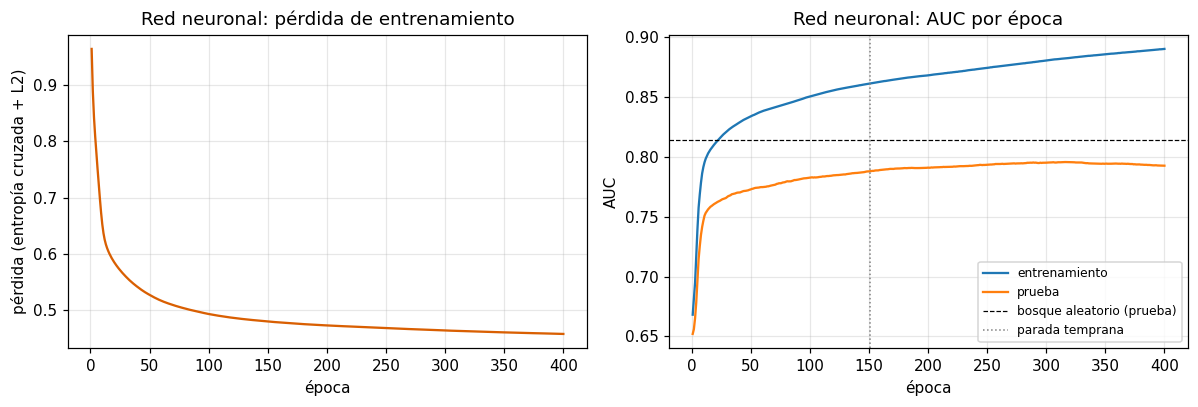

In [15]:
RN, RF = "Red neuronal (MLP)", "Bosque aleatorio"
rn = ajustados[RN].best_estimator_
print("arquitectura elegida:", rn[-1].hidden_layer_sizes, " alpha:", rn[-1].alpha,
      " épocas hasta la parada temprana:", rn[-1].n_iter_)

esc = StandardScaler().fit(X_tr)
A_tr, A_te = esc.transform(X_tr), esc.transform(X_te)
red = clone(rn[-1]).set_params(early_stopping=False)
EPOCAS = 400
perd, auc_e_tr, auc_e_te = [], [], []
for e in range(EPOCAS):
    red.partial_fit(A_tr, y_tr, classes=[0, 1])
    perd.append(red.loss_)
    auc_e_tr.append(roc_auc_score(y_tr, red.predict_proba(A_tr)[:, 1]))
    auc_e_te.append(roc_auc_score(y_te, red.predict_proba(A_te)[:, 1]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(range(1, EPOCAS + 1), perd, color="#d95f02")
a1.set_xlabel("época"); a1.set_ylabel("pérdida (entropía cruzada + L2)"); a1.set_title("Red neuronal: pérdida de entrenamiento")
a2.plot(range(1, EPOCAS + 1), auc_e_tr, label="entrenamiento")
a2.plot(range(1, EPOCAS + 1), auc_e_te, label="prueba")
a2.axhline(roc_auc_score(y_te, PROBA[RF]), color="k", ls="--", lw=0.8, label="bosque aleatorio (prueba)")
a2.axvline(rn[-1].n_iter_, color="gray", ls=":", lw=1, label="parada temprana")
a2.set_xlabel("época"); a2.set_ylabel("AUC"); a2.set_title("Red neuronal: AUC por época"); a2.legend(fontsize=8)
guardar("red_epocas")
plt.show()

In [16]:
# 2) diferencia de AUC (bosque - red) con bootstrap pareado
dif = []
for b in B:
    if len(np.unique(y_te[b])) < 2:
        continue
    dif.append(roc_auc_score(y_te[b], PROBA[RF][b]) - roc_auc_score(y_te[b], PROBA[RN][b]))
dif = np.array(dif)
lo, hi = np.percentile(dif, [2.5, 97.5])
print(f"AUC bosque {roc_auc_score(y_te, PROBA[RF]):.3f}  red {roc_auc_score(y_te, PROBA[RN]):.3f}")
print(f"diferencia (bosque - red) {dif.mean():+.3f}, IC95 [{lo:+.3f}, {hi:+.3f}], "
      f"remuestreos con la red igual o mejor: {np.mean(dif <= 0):.1%}")

# 3) estabilidad frente a la semilla, 4) costo
filas = []
for nombre in (RF, RN):
    base = ajustados[nombre].best_estimator_
    aucs, t_fit = [], []
    for s in range(5):
        m = clone(base).set_params(modelo__random_state=s)
        if nombre == RF:
            m.set_params(modelo__n_jobs=1)          # tiempos comparables: un solo núcleo
        t0 = time.perf_counter(); m.fit(X_tr, y_tr); t_fit.append(time.perf_counter() - t0)
        aucs.append(roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]))
    t0 = time.perf_counter()
    for _ in range(20):
        m.predict_proba(X_te[:1])
    t_pred = (time.perf_counter() - t0) / 20
    if nombre == RN:
        n_par = sum(w.size for w in m[-1].coefs_) + sum(b.size for b in m[-1].intercepts_)
        tam = f"{n_par} pesos"
    else:
        tam = f"{sum(t.tree_.node_count for t in m[-1].estimators_)} nodos ({len(m[-1].estimators_)} árboles)"
    filas.append({"modelo": nombre, "AUC prueba (5 semillas)": f"{np.mean(aucs):.3f} ± {np.std(aucs):.3f}",
                  "AUC mín–máx": f"{min(aucs):.3f}–{max(aucs):.3f}",
                  "entrenamiento [s]": round(np.mean(t_fit), 2),
                  "predicción de 1 manzana [ms]": round(1000 * t_pred, 2), "tamaño": tam})
comp_rn = pd.DataFrame(filas).set_index("modelo")
comp_rn.to_csv(os.path.join(FIG, "tabla_red_vs_bosque.csv"))
comp_rn

AUC bosque 0.814  red 0.786
diferencia (bosque - red) +0.029, IC95 [+0.011, +0.047], remuestreos con la red igual o mejor: 0.1%


,AUC prueba (5 semillas),AUC mín–máx,entrenamiento [s],predicción de 1 manzana [ms],tamaño
modelo,,,,,
Bosque aleatorio,0.814 ± 0.001,0.812–0.816,0.79,10.75,41868 nodos (300 árboles)
Red neuronal (MLP),0.767 ± 0.007,0.761–0.781,0.31,0.15,1153 pesos


### 4.4 Uso práctico: intentar solo las manzanas aprobadas

Regla de decisión: el robot intenta una manzana solo si la probabilidad predicha de éxito supera un umbral.
Sobre los intentos de prueba (simulados de forma independiente) se mide la tasa de éxito de los intentos que se
harían y la fracción de manzanas que se dejarían sin intentar. Con umbral 0 el robot intenta todo (situación
actual).

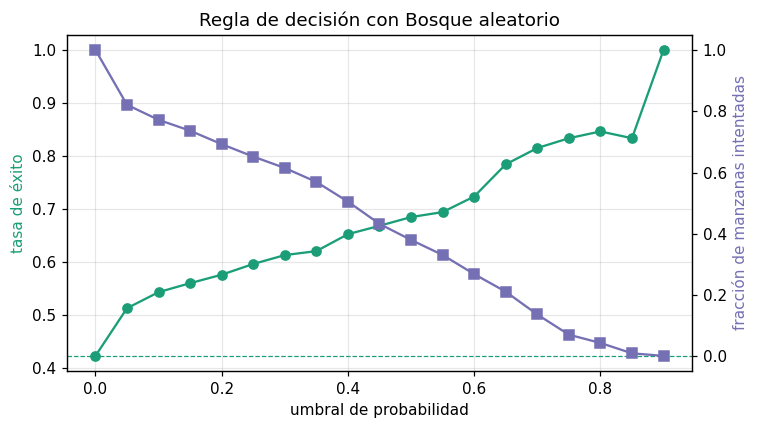

,umbral,éxito de intentos,intentadas
0,0.0,0.422,1.000
2,0.1,0.543,0.772
4,0.2,0.576,0.693
6,0.3,0.613,0.615
8,0.4,0.652,0.505
10,0.5,0.684,0.380
12,0.6,0.723,0.269
14,0.7,0.815,0.137
16,0.8,0.846,0.044
18,0.9,1.000,0.002


In [17]:
p = PROBA[mejor]
umbrales = np.linspace(0, 0.9, 19)
tasa, frac = [], []
for u in umbrales:
    m = p >= u
    tasa.append(y_te[m].mean() if m.any() else np.nan)
    frac.append(m.mean())
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(umbrales, tasa, "o-", color="#1b9e77", label="éxito de los intentos hechos")
ax1.axhline(y_te.mean(), color="#1b9e77", ls="--", lw=0.8)
ax1.set_xlabel("umbral de probabilidad"); ax1.set_ylabel("tasa de éxito", color="#1b9e77")
ax2 = ax1.twinx()
ax2.plot(umbrales, frac, "s-", color="#7570b3"); ax2.set_ylabel("fracción de manzanas intentadas", color="#7570b3")
ax2.grid(False)
plt.title(f"Regla de decisión con {mejor}")
guardar("regla_decision")
plt.show()
pd.DataFrame({"umbral": umbrales, "éxito de intentos": np.round(tasa, 3), "intentadas": np.round(frac, 3)})[::2]

## 5. Análisis comparativo — salida multiclase (¿en qué etapa falla?)

Clases: `exito`, `alcance` (la mano no llegó a la manzana), `agarre` (no quedó nada entre los dedos),
`desprendimiento` (el pedúnculo resistió o la fruta se resbaló al tirar), `retorno` (se cayó al volver),
`transporte` (se cayó camino a la canasta), `deposito` (cayó fuera de la canasta) y `tiempo`.
Las clases con menos del 3 % de los intentos se agrupan en `otro` porque no hay ejemplos suficientes para
aprenderlas.

Las clases están desbalanceadas, así que se usan pesos de clase balanceados y las métricas son la **F1
macro** (promedio sin ponderar de la F1 de cada clase: una clase rara cuenta igual que una frecuente) y la
**exactitud balanceada** (promedio de la exhaustividad por clase).

In [18]:
frec = df.etapa.value_counts(normalize=True)
raras = frec[frec < 0.03].index.tolist()
df["etapa_m"] = df.etapa.where(~df.etapa.isin(raras), "otro")
train_m, test_m = df.loc[train.index], df.loc[test.index]
z_tr, z_te = train_m.etapa_m.values, test_m.etapa_m.values
CLASES = [c for c in ["exito", "alcance", "agarre", "desprendimiento", "retorno", "transporte", "deposito",
                      "tiempo", "otro"] if c in set(df.etapa_m)]
print("agrupadas en 'otro':", raras or "ninguna")
print(train_m.etapa_m.value_counts().to_string())

MODELOS_M = {
    "Trivial": (pipe(DummyClassifier(strategy="most_frequent")), {}),
    "Regresión logística": (pipe(LogisticRegression(max_iter=3000, class_weight="balanced")),
                            {"modelo__C": [0.01, 0.1, 1, 10]}),
    "k-NN": (pipe(KNeighborsClassifier()), {"modelo__n_neighbors": [5, 11, 21], "modelo__weights": ["distance"]}),
    "SVM (RBF)": (pipe(SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
                  {"modelo__C": [0.3, 1, 3, 10], "modelo__gamma": ["scale", 0.1]}),
    "Bosque aleatorio": (pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                     random_state=SEED, n_jobs=-1)),
                         {"modelo__max_depth": [6, 12, None], "modelo__min_samples_leaf": [1, 5]}),
    "Gradient boosting": (pipe(GradientBoostingClassifier(random_state=SEED)),
                          {"modelo__n_estimators": [100, 300], "modelo__learning_rate": [0.05, 0.1],
                           "modelo__max_depth": [2, 3]}),
    "Red neuronal (MLP)": (pipe(MLPClassifier(max_iter=2000, early_stopping=True, validation_fraction=0.15,
                                              n_iter_no_change=30, random_state=SEED)),
                           {"modelo__hidden_layer_sizes": [(32,), (64, 32)], "modelo__alpha": [1e-2, 0.1, 1.0, 3.0]}),
}
filas, PRED_M, ajust_m = [], {}, {}
for nombre, (est, grid) in MODELOS_M.items():
    gs = GridSearchCV(est, grid or {"escala": [StandardScaler()]}, scoring="f1_macro", cv=CV, n_jobs=-1)
    # el MLP con parada temprana necesita etiquetas numéricas (limitación de scikit-learn): se codifican
    # como el índice en CLASES y se decodifican al predecir
    es_red = isinstance(est[-1], MLPClassifier)
    gs.fit(X_tr, np.array([CLASES.index(c) for c in z_tr]) if es_red else z_tr)
    ajust_m[nombre] = gs
    zhat = gs.predict(X_te)
    if es_red:
        zhat = np.array(CLASES)[zhat]
    PRED_M[nombre] = zhat
    filas.append({"modelo": nombre, "exactitud": accuracy_score(z_te, zhat),
                  "exactitud balanceada": balanced_accuracy_score(z_te, zhat),
                  "F1 macro": f1_score(z_te, zhat, average="macro", zero_division=0),
                  "F1 macro VC (entren.)": gs.best_score_})
res_multi = pd.DataFrame(filas).set_index("modelo").round(3)
res_multi.to_csv(os.path.join(FIG, "tabla_multiclase.csv"))
res_multi

agrupadas en 'otro': ['retorno', 'deposito']
etapa_m
exito              704
agarre             548
desprendimiento    389
alcance            185
transporte          99
otro                46


,exactitud,exactitud balanceada,F1 macro,F1 macro VC (entren.)
modelo,,,,
Trivial,0.422,0.167,0.099,0.088
Regresión logística,0.414,0.464,0.412,0.419
k-NN,0.574,0.388,0.385,0.409
SVM (RBF),0.476,0.447,0.424,0.457
Bosque aleatorio,0.591,0.464,0.461,0.497
Gradient boosting,0.627,0.454,0.455,0.480
Red neuronal (MLP),0.617,0.443,0.426,0.434


mejor modelo multiclase: Bosque aleatorio
                 precision    recall  f1-score   support

          exito       0.64      0.68      0.66       250
        alcance       0.92      0.95      0.93        37
         agarre       0.67      0.67      0.67       152
desprendimiento       0.45      0.38      0.41       107
     transporte       0.08      0.11      0.09        28
           otro       0.00      0.00      0.00        18

       accuracy                           0.59       592
      macro avg       0.46      0.46      0.46       592
   weighted avg       0.59      0.59      0.59       592



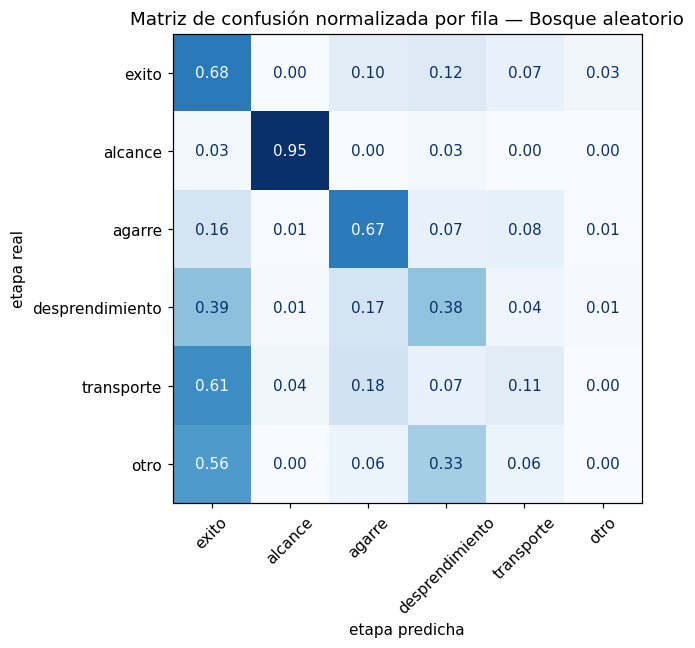

In [19]:
mejor_m = res_multi.drop("Trivial")["F1 macro"].idxmax()
print("mejor modelo multiclase:", mejor_m)
print(classification_report(z_te, PRED_M[mejor_m], labels=CLASES, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(z_te, PRED_M[mejor_m], labels=CLASES, normalize="true", ax=ax,
                                        cmap="Blues", values_format=".2f", colorbar=False)
ax.set_title(f"Matriz de confusión normalizada por fila — {mejor_m}"); ax.grid(False)
ax.set_xlabel("etapa predicha"); ax.set_ylabel("etapa real")
plt.xticks(rotation=45)
guardar("confusion_multiclase")
plt.show()

## 6. Verificación con el robot real

Los registros de las corridas de cosecha autónoma del robot real (octubre de 2026) permiten una verificación
**cualitativa** fuera de la simulación. `intentos_reales.py` extrae una fila por manzana intentada: la
posición detectada por la cámara, el giro de cintura en ese momento y si la manzana terminó en la canasta. Con
la cinemática del robot (el mismo modelo URDF) se calculan las mismas variables geométricas del dataset
(posición respecto al hombro en el marco del torso, distancias y ángulos). Todas las corridas usan la misma
política del brazo que la simulación.

**Limitaciones:** las vecinas y el píxel no se registraron igual que en la simulación, así que se entrenan
versiones de los modelos con **solo las 7 variables geométricas** (con los mismos datos simulados). Las
corridas reales mezclan versiones del código (por ejemplo, agarre programado o aprendido), incluyen giros de
cintura fuera del rango simulado (hasta −45°) y son pocas (190 intentos), así que los intervalos son anchos.
La pregunta es: **¿un modelo entrenado solo en simulación ordena los intentos reales mejor que el azar?**


robot real: 190 manzanas intentadas en 50 corridas, éxito 32.6% (simulación, prueba: 42.2%); dentro del rango simulado: 140


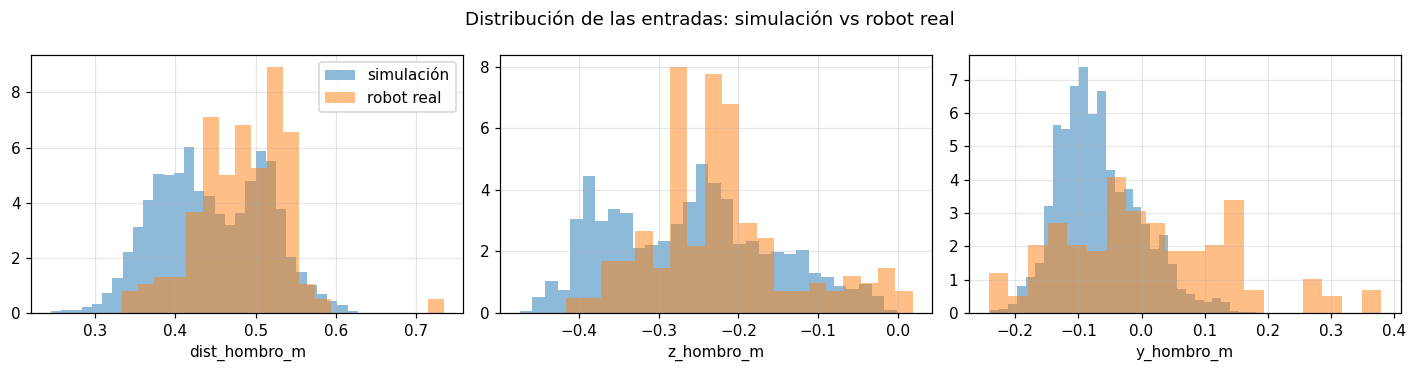

In [20]:
REAL = pd.read_csv(os.path.join(os.environ.get("ML_REALES", "datos_reales"), "intentos_reales.csv"))
GEOM = ["x_hombro_m", "y_hombro_m", "z_hombro_m", "dist_hombro_m", "dist_horiz_m", "azimut_deg", "elevacion_deg"]
y_re = REAL.exito.values
dentro = ((REAL.dist_hombro_m <= df.dist_hombro_m.max()) & (REAL.yaw_cintura_deg.abs() <= 15)).values
print(f"robot real: {len(REAL)} manzanas intentadas en {REAL.corrida.nunique()} corridas, "
      f"éxito {y_re.mean():.1%} (simulación, prueba: {y_te.mean():.1%}); dentro del rango simulado: {dentro.sum()}")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axs, ["dist_hombro_m", "z_hombro_m", "y_hombro_m"]):
    ax.hist(df[c], bins=30, density=True, alpha=0.5, label="simulación")
    ax.hist(REAL[c], bins=20, density=True, alpha=0.5, label="robot real")
    ax.set_xlabel(c)
axs[0].legend()
plt.suptitle("Distribución de las entradas: simulación vs robot real")
guardar("real_vs_sim_distribuciones")
plt.show()


In [21]:
rng_r = np.random.default_rng(SEED)
B_re = rng_r.integers(0, len(y_re), size=(2000, len(y_re)))

def ic_auc(y, p, BB):
    v = [roc_auc_score(y[b], p[b]) for b in BB if len(np.unique(y[b])) > 1]
    return np.percentile(v, [2.5, 97.5])

filas, P_RE = [], {}
for nombre, (est, grid) in MODELOS.items():
    if nombre == "Trivial":
        continue
    gs = GridSearchCV(clone(est), grid or {"escala": [StandardScaler()]}, scoring="roc_auc", cv=CV, n_jobs=-1)
    gs.fit(train[GEOM].values, y_tr)
    p_sim = gs.predict_proba(test[GEOM].values)[:, 1]
    p_re = gs.predict_proba(REAL[GEOM].values)[:, 1]
    P_RE[nombre] = p_re
    lo, hi = ic_auc(y_re, p_re, B_re)
    filas.append({"modelo": nombre, "AUC simulación (prueba)": roc_auc_score(y_te, p_sim),
                  "AUC robot real": roc_auc_score(y_re, p_re), "IC95 real": f"[{lo:.3f}, {hi:.3f}]",
                  "AUC real (dentro del rango)": roc_auc_score(y_re[dentro], p_re[dentro]),
                  "Brier real": brier_score_loss(y_re, p_re), "P media predicha": p_re.mean()})
res_real = pd.DataFrame(filas).set_index("modelo").round(3)
res_real.to_csv(os.path.join(FIG, "tabla_robot_real.csv"))
print(f"tasa de éxito real {y_re.mean():.3f}; una sola variable, la altura z (AUC real): "
      f"{roc_auc_score(y_re, REAL.z_hombro_m):.3f}")
res_real


tasa de éxito real 0.326; una sola variable, la altura z (AUC real): 0.720


,AUC simulación (prueba),AUC robot real,IC95 real,AUC real (dentro del rango),Brier real,P media predicha
modelo,,,,,,
Regresión logística,0.745,0.755,"[0.677, 0.827]",0.760,0.202,0.463
k-NN,0.807,0.677,"[0.596, 0.751]",0.699,0.224,0.382
SVM (RBF),0.806,0.562,"[0.474, 0.646]",0.624,0.265,0.294
Bosque aleatorio,0.815,0.636,"[0.548, 0.713]",0.674,0.236,0.318
Gradient boosting,0.804,0.638,"[0.546, 0.717]",0.689,0.233,0.325
Red neuronal (MLP),0.774,0.683,"[0.598, 0.760]",0.730,0.215,0.340


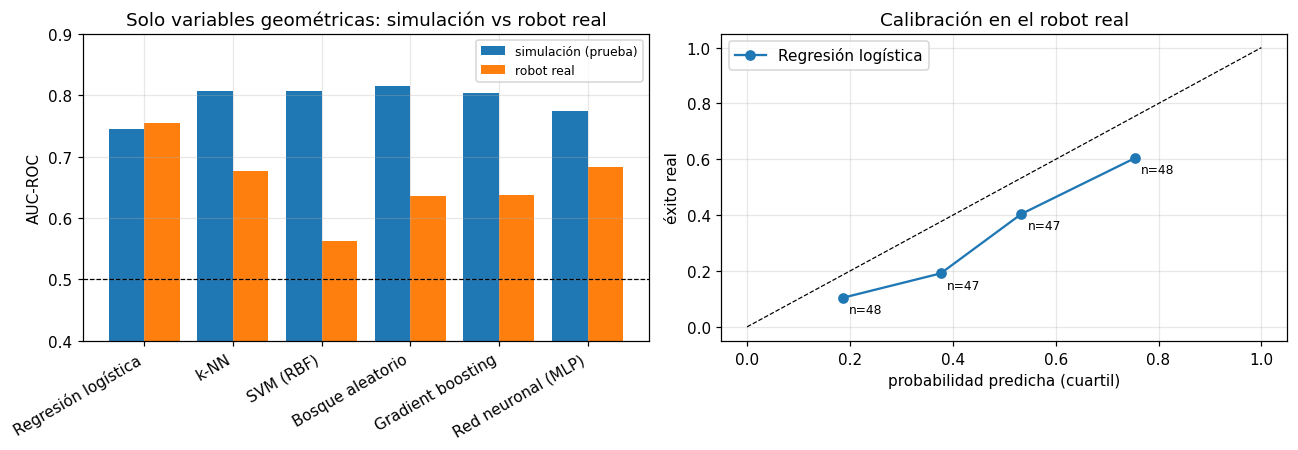

mejor en el robot real: Regresión logística


In [22]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(res_real))
a1.bar(x - 0.2, res_real["AUC simulación (prueba)"], 0.4, label="simulación (prueba)")
a1.bar(x + 0.2, res_real["AUC robot real"], 0.4, label="robot real")
a1.axhline(0.5, color="k", ls="--", lw=0.8)
a1.set_xticks(x, res_real.index, rotation=30, ha="right"); a1.set_ylim(0.4, 0.9); a1.set_ylabel("AUC-ROC")
a1.set_title("Solo variables geométricas: simulación vs robot real"); a1.legend(fontsize=8)
mejor_re = res_real["AUC robot real"].idxmax()
q = pd.qcut(P_RE[mejor_re], 4, duplicates="drop")
cal = pd.DataFrame({"p": P_RE[mejor_re], "y": y_re}).groupby(q, observed=True).agg(p=("p", "mean"), y=("y", "mean"),
                                                                                    n=("y", "size"))
a2.plot(cal.p, cal.y, "o-", label=mejor_re)
a2.plot([0, 1], [0, 1], "k--", lw=0.8)
for _, r in cal.iterrows():
    a2.annotate(f"n={int(r.n)}", (r.p, r.y), textcoords="offset points", xytext=(4, -10), fontsize=8)
a2.set_xlabel("probabilidad predicha (cuartil)"); a2.set_ylabel("éxito real"); a2.legend()
a2.set_title("Calibración en el robot real")
guardar("robot_real")
plt.show()
print("mejor en el robot real:", mejor_re)


## 7. Uso del modelo para decidir: elegir el giro de cintura (experimento en simulación)

Un modelo predictivo también puede usarse para **decidir**: antes de intentar, el robot puede girar la cintura
(entre −15° y +15°, el rango de los datos) al ángulo que el bosque aleatorio considera más favorable. Para
cada giro candidato se recalculan las entradas sin mover nada (el árbol queda quieto y gira el robot; solo
cuentan los giros en que la cámara ve la manzana entera). Que un giro tenga mayor probabilidad *predicha* no
garantiza que *cause* más éxito: por eso se comprueba con un experimento en simulación
(`cosecha_cintura.py`, misma semilla, árboles independientes), con tres grupos:

* **mantener** (línea base): el giro inicial, como en el dataset. Ojo: el generador de árboles ya coloca la
  manzana objetivo a la vista y dentro del espacio alcanzable con ese giro, así que la línea base es exigente;
* **modelo**: el giro de mayor probabilidad predicha;
* **aleatorio** (control): un giro visible al azar, para separar el efecto del modelo del efecto de girar.

Se compara la tasa de éxito con intervalos de confianza (*bootstrap*) y una prueba de dos proporciones.


,intentos,éxito,IC95,P predicha (giro usado),P predicha (giro inicial),giró (> 0.5°)
modo,,,,,,
aleatorio,600,0.342,"[0.305, 0.380]",0.342,0.333,0.945
mantener,600,0.313,"[0.275, 0.348]",0.316,0.316,0.000
modelo,600,0.425,"[0.385, 0.467]",0.447,0.336,0.945


modelo - mantener: +0.112  IC95 [+0.060, +0.163]  p = 0.000
modelo - aleatorio: +0.083  IC95 [+0.028, +0.138]  p = 0.003
aleatorio - mantener: +0.028  IC95 [-0.027, +0.085]  p = 0.296


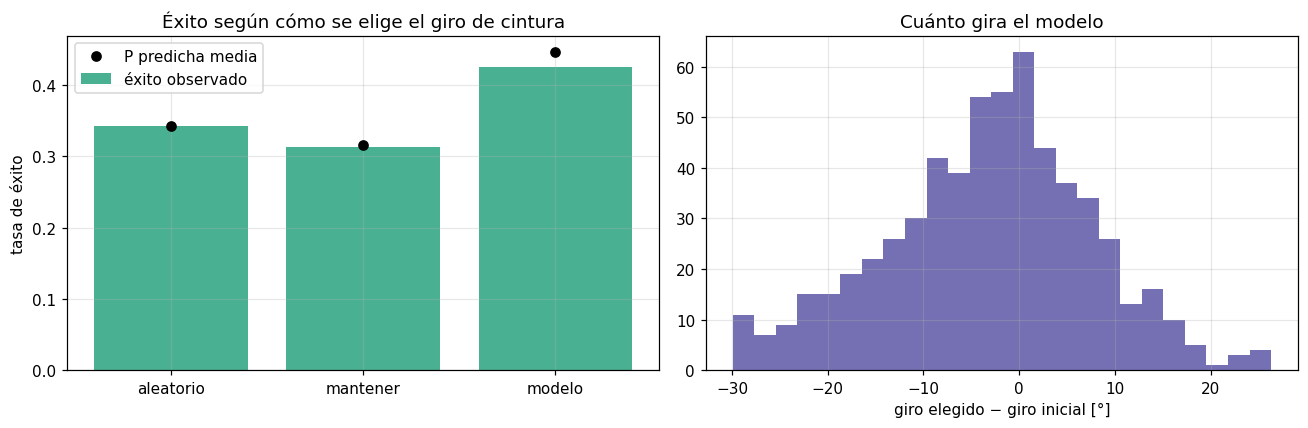

In [23]:
from math import erf, sqrt
from IPython.display import display
CINT = os.environ.get("ML_CINTURA", "datos_cintura")
arch = [f for f in sorted(glob.glob(os.path.join(CINT, "*.csv"))) if "prueba" not in os.path.basename(f)]
if not arch:
    print("todavía no hay corridas de cosecha_cintura.py en", CINT)
else:
    cz = pd.concat([pd.read_csv(f) for f in arch], ignore_index=True)
    rng_c = np.random.default_rng(SEED)
    filas = []
    for modo, g in cz.groupby("modo_cintura"):
        y = g.exito.values
        bs = [y[rng_c.integers(0, len(y), len(y))].mean() for _ in range(2000)]
        filas.append({"modo": modo, "intentos": len(y), "éxito": y.mean(),
                      "IC95": f"[{np.percentile(bs, 2.5):.3f}, {np.percentile(bs, 97.5):.3f}]",
                      "P predicha (giro usado)": g.p_elegido.mean(), "P predicha (giro inicial)": g.p_inicial.mean(),
                      "giró (> 0.5°)": (abs(g.yaw_elegido_deg - g.yaw_inicial_deg) > 0.5).mean()})
    res_cint = pd.DataFrame(filas).set_index("modo").round(3)
    res_cint.to_csv(os.path.join(FIG, "tabla_cintura.csv"))
    display(res_cint)

    def dos_prop(a, b):
        n1, n2, p1, p2 = len(a), len(b), a.mean(), b.mean()
        pp = (a.sum() + b.sum()) / (n1 + n2)
        z = (p1 - p2) / sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
        bs = [a[rng_c.integers(0, n1, n1)].mean() - b[rng_c.integers(0, n2, n2)].mean() for _ in range(2000)]
        return p1 - p2, np.percentile(bs, [2.5, 97.5]), 2 * (1 - 0.5 * (1 + erf(abs(z) / sqrt(2))))
    y_of = {m: g.exito.values for m, g in cz.groupby("modo_cintura")}
    for a, b in [("modelo", "mantener"), ("modelo", "aleatorio"), ("aleatorio", "mantener")]:
        if a in y_of and b in y_of:
            d, (lo, hi), pv = dos_prop(y_of[a], y_of[b])
            print(f"{a} - {b}: {d:+.3f}  IC95 [{lo:+.3f}, {hi:+.3f}]  p = {pv:.3f}")

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.bar(res_cint.index, res_cint["éxito"], color="#1b9e77", alpha=0.8, label="éxito observado")
    a1.plot(res_cint.index, res_cint["P predicha (giro usado)"], "ko", label="P predicha media")
    a1.set_ylabel("tasa de éxito"); a1.set_title("Éxito según cómo se elige el giro de cintura"); a1.legend()
    if "modelo" in y_of:
        g = cz[cz.modo_cintura == "modelo"]
        a2.hist(g.yaw_elegido_deg - g.yaw_inicial_deg, bins=25, color="#7570b3")
        a2.set_xlabel("giro elegido − giro inicial [°]"); a2.set_title("Cuánto gira el modelo")
    guardar("cintura")
    plt.show()


## 8. Cadena v5: un predictor reentrenado para las políticas nuevas

El primer modelo mostró que el fallo se puede anticipar y, sobre todo, **dónde** se concentra (manzanas lejanas
o bajas, fallas de agarre y de desprendimiento). Con esa información se diseñó después una cadena nueva de
políticas (v5): un alcance que tiene en cuenta la fruta (AppleArmPose-v5), un **mapa de apuntado** que elige el
giro de cintura y la dirección de la palma (una red que estima la probabilidad de que el alcance llegue, `Q`),
el agarre aprendido con los dedos congelados al cerrar, un giro de muñeca de 60° y dedos más rígidos antes de
tirar del pedúnculo.

Se recolectó un dataset nuevo con esa cadena (`cosecha_v5.py`, el mismo mundo y las mismas entradas que el
original, calculadas con la cintura ya girada al ángulo elegido; todas las manzanas se intentan). Semillas 20 y
21 para entrenamiento y 22 para prueba. Se comparan los mismos modelos y dos referencias:

* la **Q del mapa de apuntado**, la predicción que la cadena ya trae (solo mira el alcance);
* el **bosque de la cadena v1 sin reentrenar**, para ver si el modelo viejo sigue sirviendo.

'cadena v1: 2563 intentos, éxito 37.2%  |  cadena v5: 1771 intentos (entrenamiento 1185, prueba 586), éxito 68.4%'

,cadena v1,cadena v5
etapa,,
exito,0.372,0.684
alcance,0.087,0.113
agarre,0.273,0.070
desprendimiento,0.194,0.099
retorno,0.021,0.002
transporte,0.050,0.029
deposito,0.004,0.002


'  Trivial                AUC-VC 0.500  prueba 0.500  '

"  Regresión logística    AUC-VC 0.851  prueba 0.856  {'modelo__C': 10}"

"  k-NN                   AUC-VC 0.840  prueba 0.840  {'modelo__n_neighbors': 41, 'modelo__weights': 'distance'}"

"  SVM (RBF)              AUC-VC 0.847  prueba 0.860  {'modelo__C': 1, 'modelo__gamma': 0.03}"

... (2 outputs left out)

"  Red neuronal (MLP)     AUC-VC 0.816  prueba 0.838  {'modelo__alpha': 0.01, 'modelo__hidden_layer_sizes': (32, 16)}"

,exactitud,IC95 exactitud,exactitud balanceada,precisión,exhaustividad,F1,AUC-ROC,IC95 AUC,Brier,AUC-VC (entren.)
modelo,,,,,,,,,,
Trivial,0.652,"[0.614, 0.693]",0.500,0.652,1.000,0.789,0.500,"[0.500, 0.500]",0.348,0.500
Regresión logística,0.831,"[0.800, 0.860]",0.787,0.830,0.932,0.878,0.856,"[0.820, 0.887]",0.129,0.851
k-NN,0.814,"[0.782, 0.845]",0.765,0.814,0.927,0.867,0.840,"[0.802, 0.873]",0.144,0.840
SVM (RBF),0.819,"[0.788, 0.850]",0.769,0.815,0.935,0.871,0.860,"[0.824, 0.890]",0.132,0.847
Bosque aleatorio,0.829,"[0.800, 0.860]",0.787,0.831,0.927,0.876,0.853,"[0.814, 0.886]",0.127,0.859
Gradient boosting,0.824,"[0.794, 0.853]",0.781,0.827,0.924,0.873,0.855,"[0.817, 0.888]",0.128,0.853
Red neuronal (MLP),0.823,"[0.790, 0.852]",0.782,0.829,0.916,0.871,0.838,"[0.800, 0.875]",0.139,0.816
Q del mapa de apuntado (referencia),0.805,"[0.771, 0.836]",0.731,0.780,0.976,0.867,0.862,"[0.824, 0.894]",0.165,NaN
"Bosque de la cadena v1, sin reentrenar",0.679,"[0.640, 0.715]",0.723,0.891,0.579,0.702,0.858,"[0.824, 0.889]",0.219,NaN


,comparación,diferencia AUC,IC95,diferencia Brier,IC95 Brier
0,Bosque aleatorio − Q del mapa de apuntado,-0.009,"[-0.034, +0.014]",-0.038,"[-0.053, -0.021]"
1,Bosque aleatorio − Bosque de la cadena v1,-0.006,"[-0.029, +0.015]",-0.092,"[-0.117, -0.069]"


,umbral,intentados,éxito de los intentados,cosechas perdidas (de las posibles)
0,0.0,1.000,0.652,0.000
1,0.3,0.811,0.785,0.024
2,0.5,0.727,0.831,0.073
3,0.6,0.705,0.845,0.086
4,0.7,0.635,0.871,0.152
5,0.8,0.561,0.878,0.243


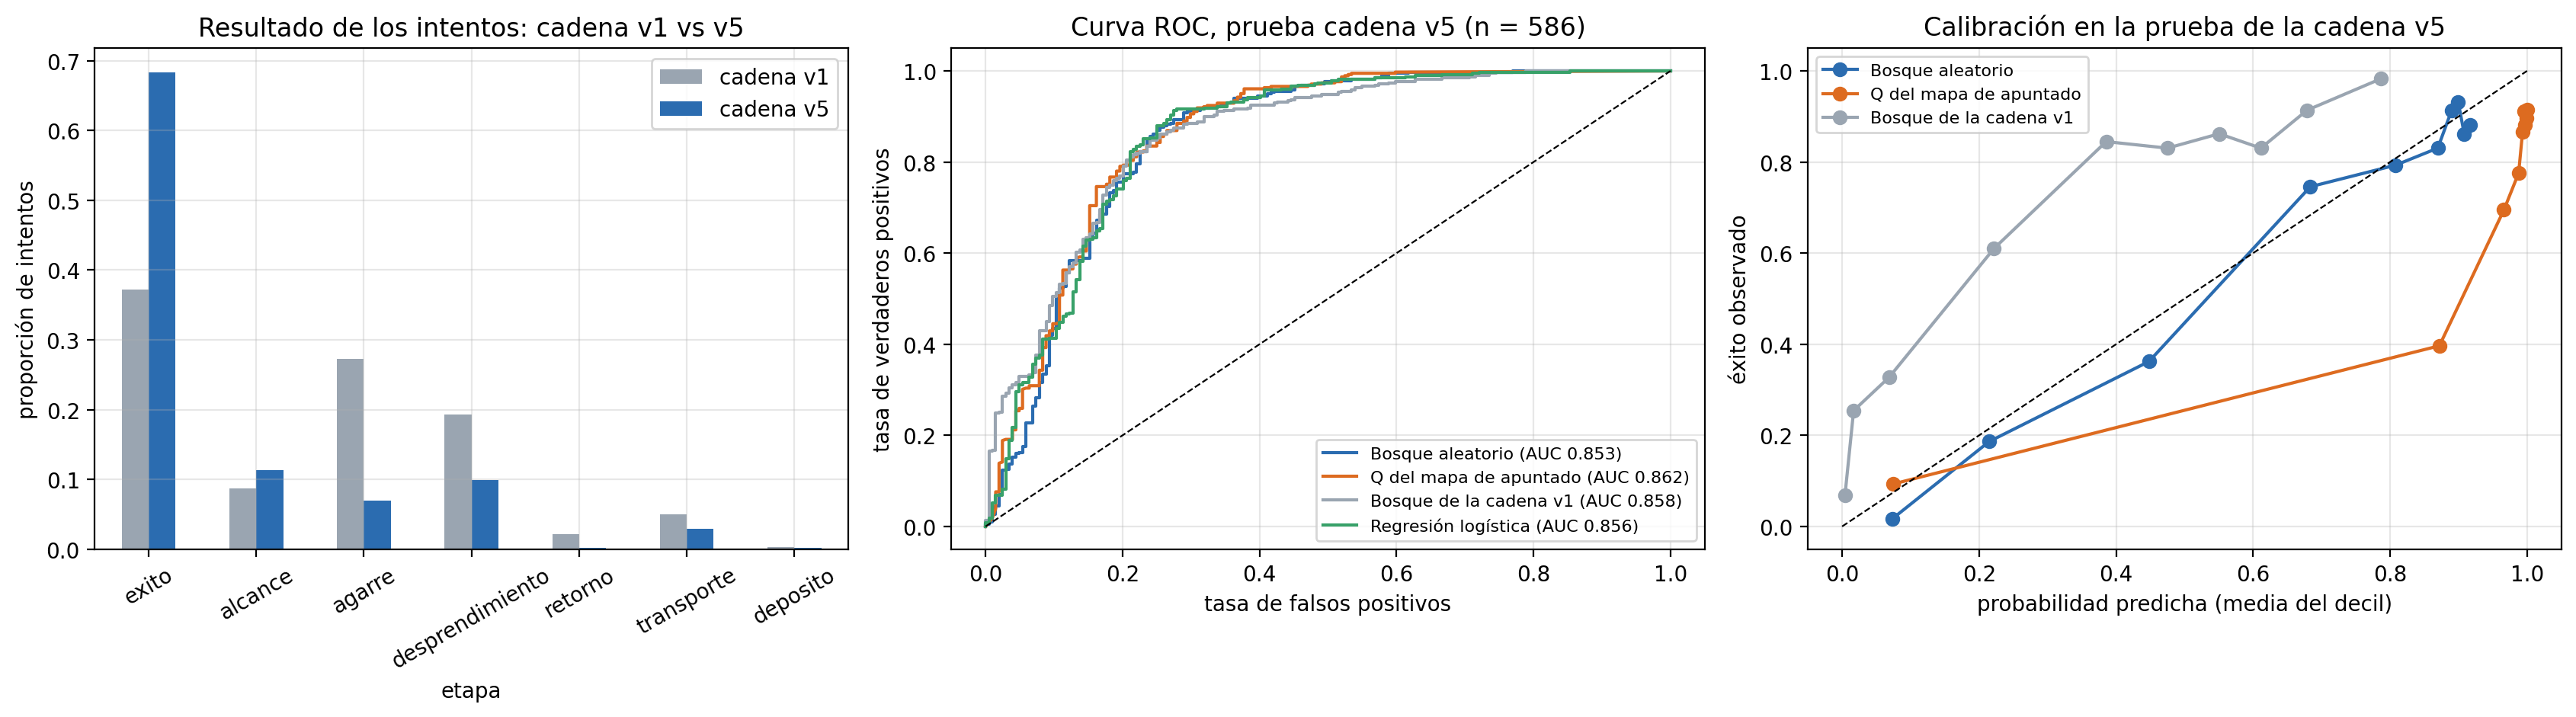

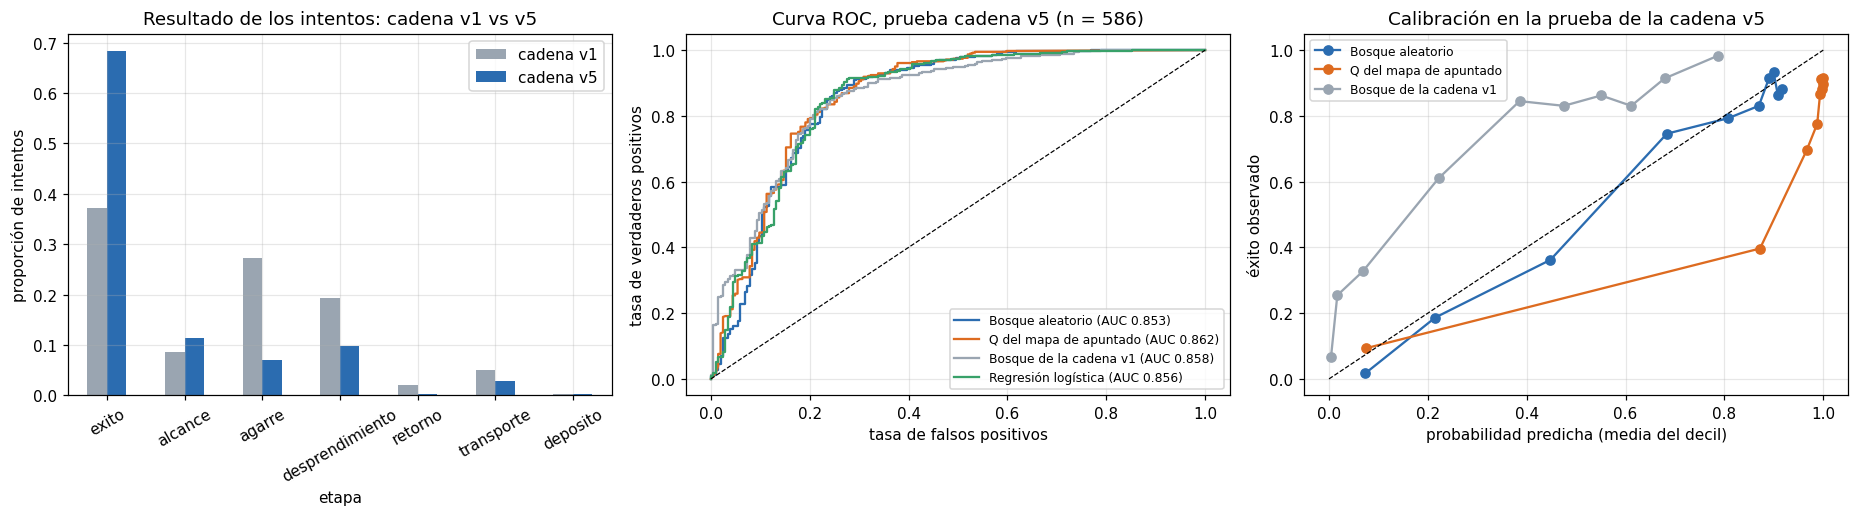

In [24]:
import analisis_v5
R5 = analisis_v5.correr(mostrar=display)
from IPython.display import Image
Image(os.path.join(FIG, "cadena_v5.png"))

## 9. Conclusiones

* **Se puede predecir el éxito antes de intentar.** El bosque aleatorio ordena los intentos simulados con
  AUC-ROC 0,814 [0,78; 0,85] (exactitud 0,718 frente a 0,578 del clasificador trivial). Todos los modelos superan
  al trivial; la regresión logística es la más débil (la relación no es lineal).
* **Lo que importa es la geometría.** La distancia y la posición de la manzana respecto al hombro explican casi
  todo lo predecible; las manzanas muy bajas casi nunca se cosechan. Las vecinas visibles aportan poco.
* **Red neuronal vs bosque.** La MLP (32-16, parada temprana) obtiene AUC 0,786; el bootstrap pareado da +0,029
  [+0,011; +0,047] a favor del bosque (diferencia significativa). La red es más sensible a la semilla y por época
  solo sobreajusta; es más pequeña y rápida, pero eso no importa en este uso.
* **Más datos:** el bosque ya está cerca de su techo; el boosting y la red siguen mejorando con más intentos.
* **Multiclase:** la etapa del fallo se predice bien solo si depende de la geometría (alcance F1 0,93, agarre
  0,67). Las caídas después de arrancar la fruta dependen de la calidad del agarre y no se anticipan
  (transporte F1 0,09).
* **Robot real (190 intentos):** con solo variables geométricas, la regresión logística mantiene su desempeño
  (AUC 0,755 [0,68; 0,83]) y los modelos flexibles caen (bosque 0,64, SVM 0,56): lo que mejor funciona en
  simulación no es lo que mejor se transfiere. Los modelos sobreestiman el éxito real.
* **Uso para decidir:** elegir el giro de cintura con el bosque subió el éxito simulado de 31,3 % a 42,5 %
  (+11,2 puntos, IC 95 % [+5,7; +16,7], p < 0,001); girar al azar no mejora significativamente (+2,8, p = 0,30).
  Las probabilidades predichas coincidieron con el éxito observado en los tres grupos.
* **Cadena v5 (diseñada después del primer modelo):** en el mismo mundo simulado cosecha el 68,4 % (frente a
  37,2 %); los fallos de agarre bajan de 27 % a 7 % y los de desprendimiento de 19 % a 10 %. El predictor
  reentrenado (bosque, elegido por validación cruzada) logra AUC 0,853 [0,81; 0,89]; todos los modelos quedan en
  0,84–0,86 y ordenan igual que la Q del mapa de apuntado (0,862) y que el bosque viejo sin reentrenar (0,858).
  La ganancia está en la **calibración**: Brier 0,127 frente a 0,165 (Q) y 0,219 (bosque viejo), ambas
  diferencias significativas. Con P ≥ 0,5 se intenta el 73 % de las manzanas, con 83 % de éxito, perdiendo el 7 %
  de las cosechas posibles. Al cambiar las políticas, el orden se conserva pero las probabilidades se deben
  reentrenar.
* **Limitaciones:** datos de entrenamiento solo simulados (física del agarre y del pedúnculo aproximada); la
  verificación real es pequeña, con versiones mezcladas y sin vecinas ni píxel; no se usa la distancia al tronco;
  cada predictor vale para las políticas con que se generaron sus datos; el experimento de cintura no se probó en el robot real.


In [25]:
print("Resumen binario (prueba):")
print(res_bin[["exactitud", "F1", "AUC-ROC", "IC95 AUC", "Brier"]].to_string())
print("\nResumen multiclase (prueba):")
print(res_multi.to_string())

Resumen binario (prueba):
                     exactitud     F1  AUC-ROC        IC95 AUC  Brier
modelo                                                               
Trivial                  0.578  0.000    0.500  [0.500, 0.500]  0.422
Regresión logística      0.666  0.566    0.747  [0.704, 0.785]  0.204
k-NN                     0.704  0.632    0.772  [0.733, 0.809]  0.195
SVM (RBF)                0.682  0.569    0.780  [0.742, 0.818]  0.200
Bosque aleatorio         0.718  0.648    0.814  [0.780, 0.847]  0.174
Gradient boosting        0.686  0.599    0.796  [0.759, 0.830]  0.185
Red neuronal (MLP)       0.694  0.616    0.786  [0.747, 0.819]  0.189

Resumen multiclase (prueba):
                     exactitud  exactitud balanceada  F1 macro  F1 macro VC (entren.)
modelo                                                                               
Trivial                  0.422                 0.167     0.099                  0.088
Regresión logística      0.414                 0.464    